## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Sebastian Diaquive Castro" # @param {"type":"string"}
carnet = 1000107262 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

## Red social con grafos
El problema consiste en analizar las conexiones de amistad de cada usuario dentro de una plataforma de red social, consiste usar como vertice a cada usaurio que este registrado, y las amistades de dicho usuario se mostraran mediante una flecha o arista, mediante el recorrido BFS y DFS se observara el recorrido mas rapido para hallar a cualquiera de los usuarios.

## 2) Requerimientos **[2 pts]**

### **Lista requerimientos funcionales:**

**-RQF(01):** El codigo no empleara librerias, los recorridos sera haran manualmente.

**-RQF(02):** Sera un programa modular con el fin de realizar ajustes rapidos.

**-RQF(03):** Se empleara un menu interactivo para que el usuario pueda navegar entre las diferentes alternativas que tendra para ver los recorridos.

**-RQF(04):** Se hara uso de una cola para mostrar el orden de visita y grado en el que se encuentra cada persona dentro del grafo.

**-RQF(05):** El usuario podra seleccionar la persona por la cual empezara el recorrido que desea.

**-RQF(06):** El usuario podra ver las dos amistades que se conectan con la persona que busque y podra agregar nuevos usuarios si asi se desea.

### **Lista requerimientos no funcionales:**

**-RQNF(01):** El codigo debe tener indicaciones y enunciados entendibles para que cualquier persona sea capaz de entender la informacion que se presenta.

**-RQNF(02):** Debe ser un codigo eficiente y de respuesta rapida.

**-RQNF(03):** Se utilizara el programa phyton dado que es el que mejor se adapta y facilita a la hora de programar.





## 3) Historias de usuario **[2 pts]**

**-HU(01):**

Caso: Uso del menu.

Exito: Se selecciono adecuadamente un numero del 1 al 6.

Error: El menu llevo a una opcion no seleccionada, o no dirigio al usuario a ningun lado.

**-HU(02):**

Caso: Ingresar el nombre de algun usuario para hacer el recorrido.

Exito: Se hizo adecuadamente el recorrido y se imprimio para visualizarlo.

Error: No se muestra nada al usuario, realiza un recorrido erroneo, no se ejecuta la opcion.

**-HU(03):**

Caso: Ingresar un nuevo usuario.

Exito: Se guardo adecuadamente el nombre del usuario que se desea agregar.

Error: No se almacena en el grafo el nuevo usuario, se guarda y se borra el nuevo usuario, no se ejecuta la opcion.


## 4) Diagramas de flujo **[5 pts]**

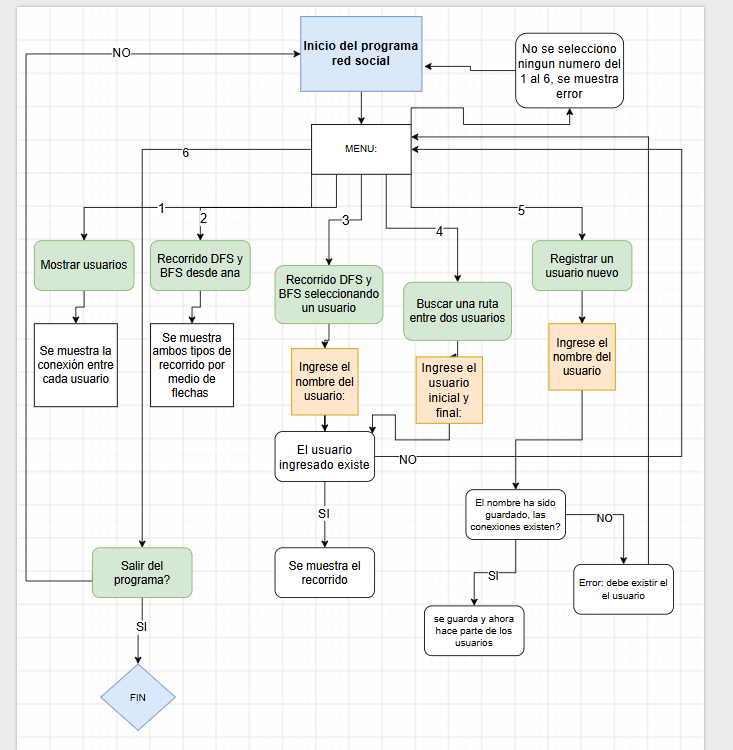

En el diagrama se puede observar como el usuario puede interactuar con el menu, a la hora de iniciar recorridos o buscar la conexion entre dos usuarios el dato debe existir para que se muestre el recorrido de lo contrario se reinicia el programa, a la hora de elegir una opcion del menu debe estar dentro de 1 al 6 para poder acceder, a la hora de ingresar un nuevo usuario cualquier clase de dato se toma como el nombre y se agrega al grafo, y siempre esta la opcion de repetirlo las veces que se desee el menu o finalizar el programa.


### 5) Análisis de complejidad **[15 pts]**

### **Mejor caso:**

**O(1)**

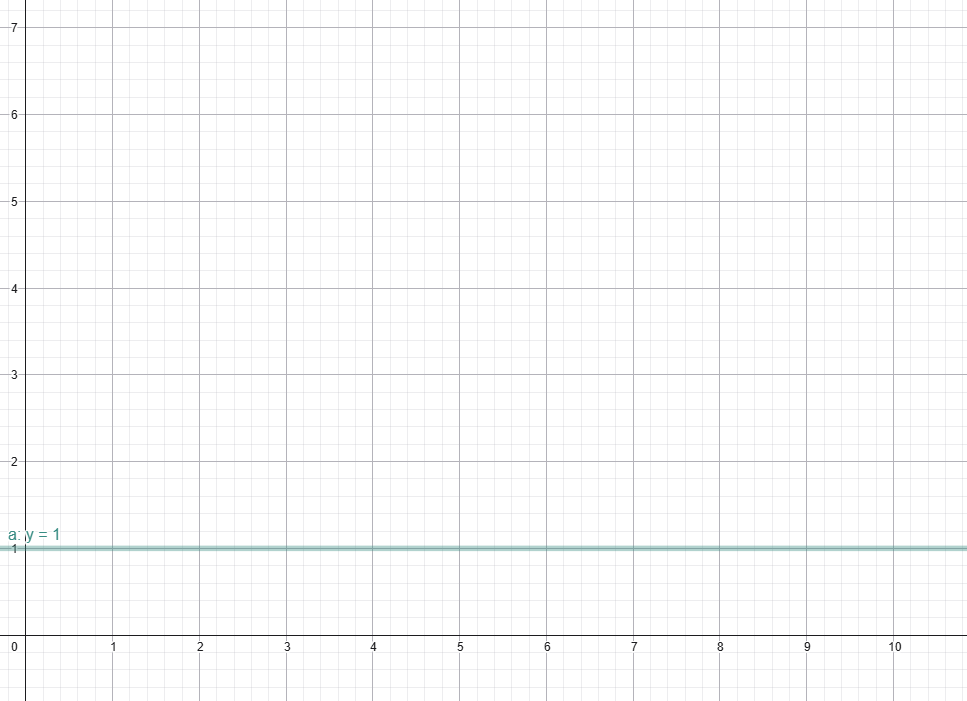

### **Peor caso:**

**O(n^2)**

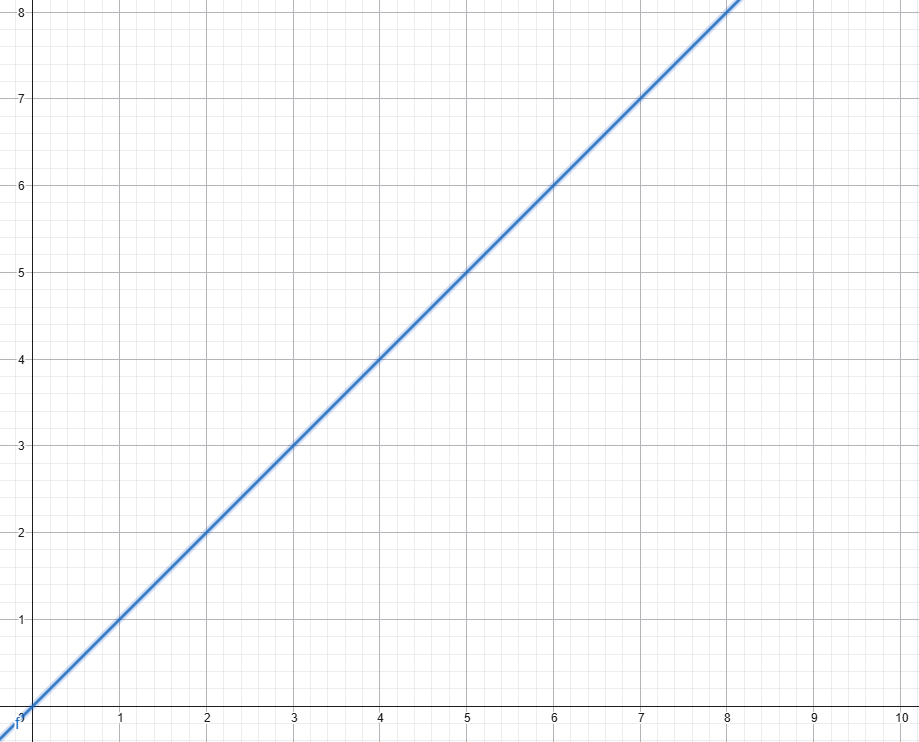

**JUSTIFICACION**

El mejor caso ocurre cuando el recorrido termina casi de inmediato ya que el usuario
inicial entre otros datos no se registran todavia, es decir que no existirian al iniciar el codigo y de esta forma al hacer busquedas o recorridos los bucles o no se iteran varias veces osea muy pocas por ende su costo es bastante bajo en el inicio. Por otro lado el peor caso debe iterar los bucles varias veces ya que debe recorrer todos los usuarios registrados o ya existentes, las amistades que tenga cada uno, esto ocaciona que se pueda generar grafo mucho mas grande al que se porporciono por el problema por esta razon queda de la forma n^2.


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
red_social = {}

def registrar_usuario(nombre):
    if nombre not in red_social:
        red_social[nombre] = []

def crear_amistad(user1, user2):
    if user1 == user2:
        print("\nUn usuario no puede agregarse asi mismo como un amigo, intentalo de nuevo.")
        return

    registrar_usuario(user1)
    registrar_usuario(user2)

    if user2 not in red_social[user1]:
        red_social[user1].append(user2)

    if user1 not in red_social[user2]:
        red_social[user2].append(user1)

def mostrar_toda_la_red():
    print("\n--- Red social ---")
    for persona in red_social:
        amigos = ", ".join(red_social[persona])
        print(persona + " es amigo/a de: " + amigos)

def hacer_bfs(nodo_inicio):
    if nodo_inicio not in red_social:
        print("\nEl usuario '" + nodo_inicio + "' no se encuentra registrado en la red.")
        return

    lista_visitados = []
    cola_nodos = [[nodo_inicio, 0]]
    dicc_grados = {}
    camino_final = []

    while len(cola_nodos) != 0:
        sacado = cola_nodos.pop(0)
        nodo_actual = sacado[0]
        grado_actual = sacado[1]

        if nodo_actual not in lista_visitados:
            lista_visitados.append(nodo_actual)
            camino_final.append(nodo_actual)

            if grado_actual not in dicc_grados:
                dicc_grados[grado_actual] = []
            dicc_grados[grado_actual].append(nodo_actual)

            for vecino in red_social[nodo_actual]:
                if vecino not in lista_visitados:
                    cola_nodos.append([vecino, grado_actual + 1])

    print("\nRecorrido BFS desde el usuario " + nodo_inicio + ":")
    print(" -> ".join(camino_final))

    for g in dicc_grados:
        print("Grado/nivel " + str(g) + ": " + ", ".join(dicc_grados[g]))

def _recursion_dfs(nodo_actual, lista_visitados, camino):
    lista_visitados.append(nodo_actual)
    camino.append(nodo_actual)

    for vecino in red_social[nodo_actual]:
        if vecino not in lista_visitados:
            _recursion_dfs(vecino, lista_visitados, camino)

def hacer_dfs(nodo_inicio):
    if nodo_inicio not in red_social:
        print("\nEl usuario '" + nodo_inicio + "' no se encuentra registrado en la red.")
        return

    visitados = []
    camino_dfs = []
    _recursion_dfs(nodo_inicio, visitados, camino_dfs)

    print("\nRecorrido DFS desde " + nodo_inicio + ":")
    print(" -> ".join(camino_dfs))

def buscar_camino_corto(origen, destino):
    if origen not in red_social or destino not in red_social:
        print("\nUno de los usuarios indicados no existe o no esta registrado en la red.")
        return

    visitados = []
    cola_rutas = [[origen]]

    while len(cola_rutas) != 0:
        ruta_evaluada = cola_rutas.pop(0)
        ultimo_nodo = ruta_evaluada[-1]

        if ultimo_nodo == destino:
            print("\nSe logro encontrar la ruta:")
            print(" -> ".join(ruta_evaluada))
            print("Grados de separación entre el usuario: " + str(len(ruta_evaluada) - 1))
            return

        if ultimo_nodo not in visitados:
            visitados.append(ultimo_nodo)

            for vecino in red_social[ultimo_nodo]:
                if vecino not in visitados:
                    ruta_nueva = list(ruta_evaluada)
                    ruta_nueva.append(vecino)
                    cola_rutas.append(ruta_nueva)

    print("\nNo existe una conexión o camino entre " + origen + " y " + destino + ", ingresa otro nombre que si tenga una amistad con la persona que buscas.")

def cargar_datos_del_pdf():
    crear_amistad("Ana", "Carlos")
    crear_amistad("Ana", "Laura")
    crear_amistad("Carlos", "Mateo")
    crear_amistad("Carlos", "Sofía")
    crear_amistad("Laura", "Daniel")
    crear_amistad("Sofía", "Valentina")
    crear_amistad("Daniel", "Valentina")

def menu_principal():
    cargar_datos_del_pdf()

    opcion = "0"

    while opcion != "6":
        print("\tMENU DE RED SOCIAL")
        print("Cada uno de los nombres se debe ingresar con la primera letra en mayuscula, y se deben emplear las tildes de ser necesario, si ya ingresaste uno debes escribirlo tal cual en cuyo caso quiera buscarlo.")
        print("1. Mostrar la red de usuarios actual.")
        print("2. Iniciar el recorrido BFS y DFS desde Ana")
        print("3. Iniciar el recorrido BFS y DFS desde el usuario que deseas.")
        print("4. Buscar una ruta entre dos usuarios")
        print("5. Registrar un usuario nuevo")
        print("6. Salir")

        opcion = input("Elija alguno de los numeros que aparecen junto a cada opcion estan dentro de un intervalo del 1 al 6: ").strip()

        if opcion == "1":
            mostrar_toda_la_red()

        elif opcion == "2":
            hacer_bfs("Ana")
            hacer_dfs("Ana")

        elif opcion == "3":
            nombre_elegido = input("Usuario inicial: ").strip()
            hacer_bfs(nombre_elegido)
            hacer_dfs(nombre_elegido)

        elif opcion == "4":
            persona1 = input("Usuario inicial: ").strip()
            persona2 = input("Usuario de destino: ").strip()
            buscar_camino_corto(persona1, persona2)

        elif opcion == "5":
            nuevo_user = input("Ingrese el nombre del nuevo usuario: ").strip()

            if nuevo_user == "":
                print("\nEl nombre no puede ser un espacio vacio porfavor vuelve a ingresar el nombre")
                continue

            if nuevo_user in red_social:
                print("\nEl usuario '" + nuevo_user + "' ya se encuentra registrado en la red.")
                continue

            amigo_1 = input("Conectar con el usuario 1: ").strip()
            amigo_2 = input("Conectar con el usuario 2: ").strip()

            if amigo_1 not in red_social or amigo_2 not in red_social:
                print("\nLos dos usuarios con los que deseas bucasr una conexion deben existir en la red.")
            elif amigo_1 == amigo_2:
                print("\nDebe conectarse con dos usuarios distintos.")
            else:
                crear_amistad(nuevo_user, amigo_1)
                crear_amistad(nuevo_user, amigo_2)
                print("\nEl usuario '" + nuevo_user + "' se registro en la red.")
                mostrar_toda_la_red()

        elif opcion == "6":
            print("\nGracias por su tiempo, feliz dia.")

        else:
            print("\nEl numero ingresado debe ser del 1 al 6, porfavor vuelvalo a intentar.")

menu_principal()

## 7) Tests aplicados **[15 pts]**

In [ ]:
print("\tPRUEBA 1: RED INICIAL")
cargar_red_inicial()
mostrar_red()

print("\tPRUEBA 2: BFS DESDE ANA")
bfs("Ana")

print("\tPRUEBA 3: DFS DESDE ANA")
dfs("Ana")

print("\tPRUEBA 4: OTRO USUARIO INICIAL")
print("Usuario inicial: Sofía")
bfs("Sofía")
dfs("Sofía")

print("\tPRUEBA 5: RUTA MÁS CORTA")
print("Usuario inicial: Ana")
print("Usuario destino: Valentina")
buscar_ruta("Ana", "Valentina")
buscar_ruta("Mateo", "Daniel")

print("\tPRUEBA 6: RUTA CON USUARIO QUE NO EXISTE")
buscar_ruta("Ana", "Pepe")

print("\tPRUEBA 7: RUTA INEXISTENTE")
agregar_usuario("Isla")
buscar_ruta("Ana", "Isla")
del grafo["Isla"]

print("\tPRUEBA 8: SIN AMISTADES DUPLICADAS")
agregar_amistad("Ana", "Carlos")
agregar_amistad("Carlos", "Ana")
print("Amigos de Ana: " + ", ".join(grafo["Ana"]))
print("Amigos de Carlos: " + ", ".join(grafo["Carlos"]))

print("\tPRUEBA 9: NUEVO USUARIO CON DATOS INCORRECTOS")
nuevo_usuario("Pedro", "Ana", "Zoe")
nuevo_usuario("Pedro", "Ana", "Ana")
nuevo_usuario("Ana", "Carlos", "Laura")

print("\tPRUEBA 10: NUEVO USUARIO CORRECTO")
print("Nuevo usuario: Pedro")
print("Conectar con usuario 1: Mateo")
print("Conectar con usuario 2: Daniel")
nuevo_usuario("Pedro", "Mateo", "Daniel")

print("\tPRUEBA 11: RED ACTUALIZADA")
bfs("Ana")
dfs("Ana")
buscar_ruta("Ana", "Pedro")